In [ ]:
#Q2. 5월에 지하철 승객수가 많다?

import pandas as pd

file1 = pd.read_csv('CARD_SUBWAY_MONTH_201901.csv')
file2 = pd.read_csv('CARD_SUBWAY_MONTH_201902.csv')
file3 = pd.read_csv('CARD_SUBWAY_MONTH_201903.csv')
file4 = pd.read_csv('CARD_SUBWAY_MONTH_201904.csv')
file5 = pd.read_csv('CARD_SUBWAY_MONTH_201905.csv')
file6 = pd.read_csv('CARD_SUBWAY_MONTH_201906.csv')

result = pd.concat([file1, file2, file3, file4, file5, file6])

result['승하차총승객수'] = (result['승차총승객수'] + result['하차총승객수'])


#사용일자를 날짜 형식으로 바꾸고 승하차총승객수 합 구하기
result['사용일자'] = pd.to_datetime(result['사용일자'], format='%Y%m%d')

#달 컬럼 추가
result['연월'] = result['사용일자'].dt.to_period('M')

monthly_passengers = result.groupby('연월')['승하차총승객수'].sum().reset_index()
max_passenger_month = monthly_passengers.loc[monthly_passengers['승하차총승객수'].idxmax()]

print(monthly_passengers, '\n')
print(f'1월~6월중에 지하철 승객수가 많은 달은 {max_passenger_month['연월']}월입니다.')

        연월      승하차총승객수
0  2019-01  442746389.0
1  2019-02  379836010.0
2  2019-03  466692826.0
3  2019-04  470934348.0
4  2019-05  485718557.0
5  2019-06  442210635.0 

1월~6월중에 지하철 승객수가 많은 달은 2019-05월입니다.


In [ ]:
#Q3. 목요일에 지하철 승객수가 많다?

#요일 컬럼 추가 (0=월요일, 6=일요일)
result['요일'] = result['사용일자'].dt.dayofweek

#요일을 기준으로 데이터를 그룹화한 객체 생성
grouped = result.groupby('요일')

day_passengers = grouped['승하차총승객수'].sum().reset_index()
max_passengers_day = day_passengers.loc[day_passengers['승하차총승객수'].idxmax()]
print(max_passengers_day)

요일                 4.0
승하차총승객수    445310717.0
Name: 4, dtype: float64


In [ ]:
result

,사용일자,노선명,역명,승차총승객수,하차총승객수,등록일자,승하차총승객수,연월,요일
0,2019-01-01,2호선,을지로4가,3862.0,3728.0,20190104,7590.0,2019-01,1
1,2019-01-01,3호선,을지로3가,8104.0,7554.0,20190104,15658.0,2019-01,1
2,2019-01-01,2호선,을지로입구,22478.0,21330.0,20190104,43808.0,2019-01,1
3,2019-01-01,2호선,시청,8381.0,6049.0,20190104,14430.0,2019-01,1
4,2019-01-01,6호선,동묘앞,8045.0,8504.0,20190104,16549.0,2019-01,1
...,...,...,...,...,...,...,...,...,...
17719,2019-06-30,7호선,마들,6622.0,6116.0,20190703,12738.0,2019-06,6
17720,2019-06-30,4호선,노원,14071.0,14702.0,20190703,28773.0,2019-06,6
17721,2019-06-30,7호선,중계,9516.0,8981.0,20190703,18497.0,2019-06,6
17722,2019-06-30,7호선,하계,11645.0,11121.0,20190703,22766.0,2019-06,6


In [ ]:
file1 = pd.read_csv('CARD_SUBWAY_MONTH_201901.csv')
file1['승하차총승객수'] = (file1['승차총승객수'] + file1['하차총승객수'])

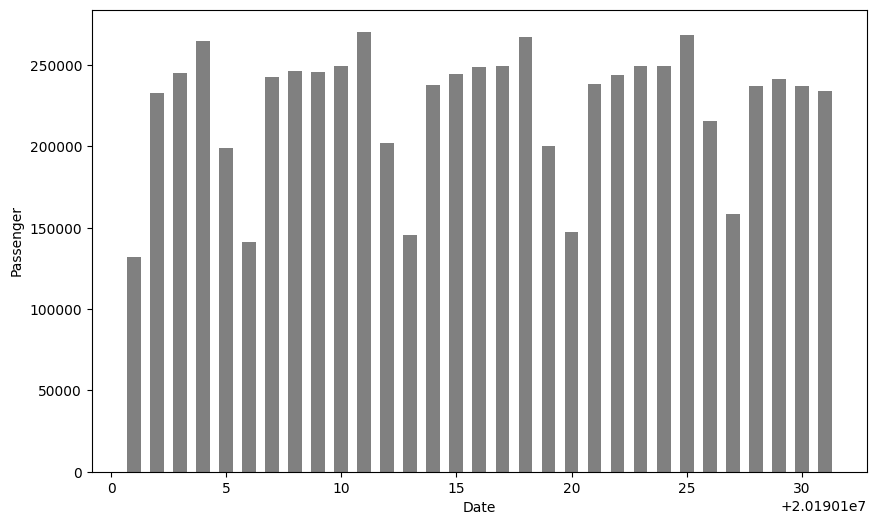

In [ ]:
import matplotlib.pyplot as plt

xs = file1['사용일자']
ys = file1['승하차총승객수']

plt.figure(figsize=(10, 6))
plt.xlabel('Date')
plt.ylabel('Passenger')

plt.bar(xs, ys, width=0.6, color='grey')
plt.show()

In [ ]:
import pandas as pd

file1 = pd.read_csv('CARD_SUBWAY_MONTH_201901.csv')
file2 = pd.read_csv('CARD_SUBWAY_MONTH_201902.csv')
file3 = pd.read_csv('CARD_SUBWAY_MONTH_201903.csv')
file4 = pd.read_csv('CARD_SUBWAY_MONTH_201904.csv')
file5 = pd.read_csv('CARD_SUBWAY_MONTH_201905.csv')
file6 = pd.read_csv('CARD_SUBWAY_MONTH_201906.csv')

result = pd.concat([file1, file2, file3, file4, file5, file6])

result['승하차총승객수'] = (result['승차총승객수'] + result['하차총승객수'])

In [ ]:
#Q5. 가장 승객이 많이 타는 승차역은?

print(result)

# '역명'을 기준으로 '승차총승객수'의 합계 구하기!!
grouped_data = result.groupby('역명')['승차총승객수'].sum().reset_index()

max_passenger_station = grouped_data.loc[grouped_data['승차총승객수'].idxmax()]

print(f"가장 승객이 많이 타는 역은 {max_passenger_station['역명']}이며, 총 승객 수는 {max_passenger_station['승차총승객수']}명입니다.")

           사용일자  노선명     역명   승차총승객수   하차총승객수      등록일자  승하차총승객수
0      20190101  2호선  을지로4가   3862.0   3728.0  20190104   7590.0
1      20190101  3호선  을지로3가   8104.0   7554.0  20190104  15658.0
2      20190101  2호선  을지로입구  22478.0  21330.0  20190104  43808.0
3      20190101  2호선     시청   8381.0   6049.0  20190104  14430.0
4      20190101  6호선    동묘앞   8045.0   8504.0  20190104  16549.0
...         ...  ...    ...      ...      ...       ...      ...
17719  20190630  7호선     마들   6622.0   6116.0  20190703  12738.0
17720  20190630  4호선     노원  14071.0  14702.0  20190703  28773.0
17721  20190630  7호선     중계   9516.0   8981.0  20190703  18497.0
17722  20190630  7호선     하계  11645.0  11121.0  20190703  22766.0
17723  20190630  6호선   태릉입구   5730.0   5214.0  20190703  10944.0

[107028 rows x 7 columns]
가장 승객이 많이 타는 역은 잠실이며, 총 승객 수는 18574323.0명입니다.


In [ ]:
#Q7. 1호선에서 가장 하차를 많이 하는 역은?

# '노선명'이 '1호선'인 행만 추출
filtered_data = result[result['노선명'] == '1호선']

print(filtered_data.head())

# '1호선'에서 가장 승객이 많이 하차하는 역을 구하기 groupby사
grouped_data = filtered_data.groupby('역명')['하차총승객수'].sum().reset_index()
max_passenger_station = grouped_data.loc[grouped_data['하차총승객수'].idxmax()]

print(f"1호선에서 가장 승객이 많이 하차하는 역은 {max_passenger_station['역명']}이며, 총 승객 수는 {max_passenger_station['하차총승객수']}명입니다.")

        사용일자  노선명    역명   승차총승객수   하차총승객수      등록일자  승하차총승객수
6   20190101  1호선   제기동  10187.0  10178.0  20190104  20365.0
7   20190101  1호선   신설동   6832.0   6930.0  20190104  13762.0
9   20190101  1호선  종로5가  13578.0  13282.0  20190104  26860.0
10  20190101  1호선    종각  20944.0  16658.0  20190104  37602.0
52  20190101  1호선   신설동   2525.0   2197.0  20190104   4722.0
1호선에서 가장 승객이 많이 하차하는 역은 가산디지털단지이며, 총 승객 수는 10571381.0명입니다.


Index(['사용일자', '노선명', '역명', '승차총승객수', '하차총승객수', '등록일자', '승하차총승객수', '연월', '요일'], dtype='object')
노선명              1호선  2호선        3호선        4호선  5호선  6호선  7호선  8호선  \
역명                                                                    
4.19민주묘지         NaN  NaN        NaN        NaN  NaN  NaN  NaN  NaN   
가능         1319667.0  NaN        NaN        NaN  NaN  NaN  NaN  NaN   
가락시장             NaN  NaN  3233294.0        NaN  NaN  NaN  NaN  NaN   
가산디지털단지   10111317.0  NaN        NaN        NaN  NaN  NaN  NaN  NaN   
가양               NaN  NaN        NaN        NaN  NaN  NaN  NaN  NaN   
...              ...  ...        ...        ...  ...  ...  ...  ...   
회기         5403827.0  NaN        NaN        NaN  NaN  NaN  NaN  NaN   
회룡         2424620.0  NaN        NaN        NaN  NaN  NaN  NaN  NaN   
회현               NaN  NaN        NaN  5583018.0  NaN  NaN  NaN  NaN   
효창공원앞            NaN  NaN        NaN        NaN  NaN  NaN  NaN  NaN   
흑석               NaN  NaN        NaN        NaN  NaN

C:\Users\purer\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 54840 (\N{HANGUL SYLLABLE HO}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
C:\Users\purer\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
C:\Users\purer\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 44221 (\N{HANGUL SYLLABLE GYEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
C:\Users\purer\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 44053 (\N{HANGUL SYLLABLE GANG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
C:\Users\purer\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
C:

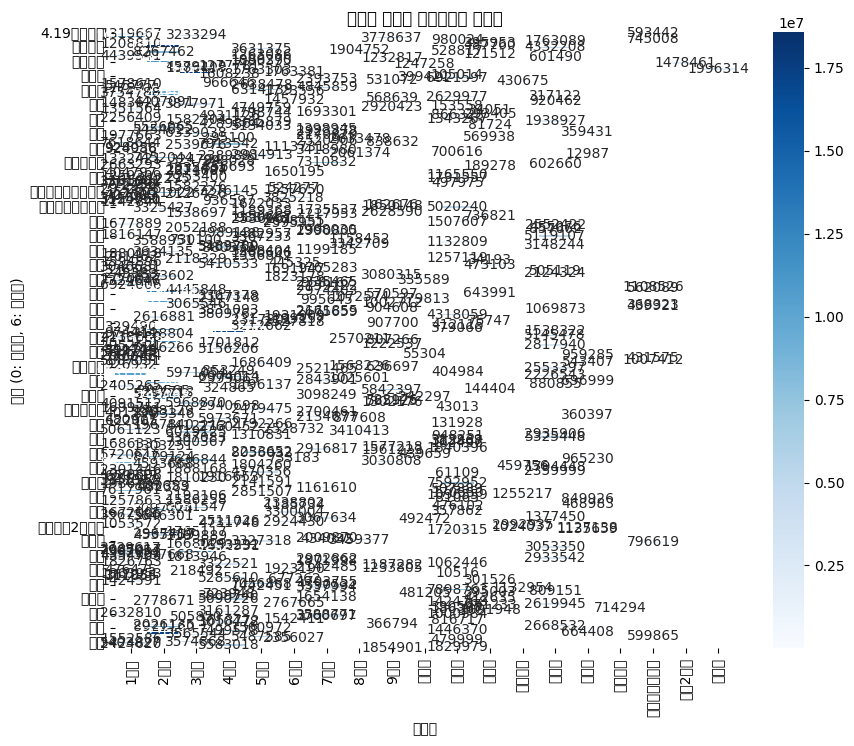

In [ ]:
#Q6 노선별(1~9호선)로 역별, 요일별 히트맵 승차승객수 비교하기

import seaborn as sns
import matplotlib.pyplot as plt

result['사용일자'] = pd.to_datetime(result['사용일자'], format='%Y%m%d')

result['연월'] = result['사용일자'].dt.to_period('M')

result['요일'] = result['사용일자'].dt.dayofweek

print(result.columns)
pivot_table = result.pivot_table(values='승차총승객수', index='역명', columns='노선명', aggfunc='sum')
print(pivot_table)

plt.figure(figsize=(10,8))
sns.heatmap(pivot_table, annot=True, fmt=".0f", cmap='Blues')

plt.title('노선별 요일별 승차승객수 히트맵')
plt.ylabel('요일 (0: 월요일, 6: 일요일)')
plt.xlabel('노선명')

plt.show()

Index(['사용일자', '노선명', '역명', '승차총승객수', '하차총승객수', '등록일자', '승하차총승객수', '연월', '요일'], dtype='object')
노선명              1호선  2호선        3호선        4호선  5호선  6호선  7호선  8호선  \
역명                                                                    
4.19민주묘지         NaN  NaN        NaN        NaN  NaN  NaN  NaN  NaN   
가능         1319667.0  NaN        NaN        NaN  NaN  NaN  NaN  NaN   
가락시장             NaN  NaN  3233294.0        NaN  NaN  NaN  NaN  NaN   
가산디지털단지   10111317.0  NaN        NaN        NaN  NaN  NaN  NaN  NaN   
가양               NaN  NaN        NaN        NaN  NaN  NaN  NaN  NaN   
...              ...  ...        ...        ...  ...  ...  ...  ...   
회기         5403827.0  NaN        NaN        NaN  NaN  NaN  NaN  NaN   
회룡         2424620.0  NaN        NaN        NaN  NaN  NaN  NaN  NaN   
회현               NaN  NaN        NaN  5583018.0  NaN  NaN  NaN  NaN   
효창공원앞            NaN  NaN        NaN        NaN  NaN  NaN  NaN  NaN   
흑석               NaN  NaN        NaN        NaN  NaN

C:\Users\purer\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 54840 (\N{HANGUL SYLLABLE HO}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
C:\Users\purer\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
C:\Users\purer\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 44221 (\N{HANGUL SYLLABLE GYEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
C:\Users\purer\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 44053 (\N{HANGUL SYLLABLE GANG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
C:\Users\purer\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
C:

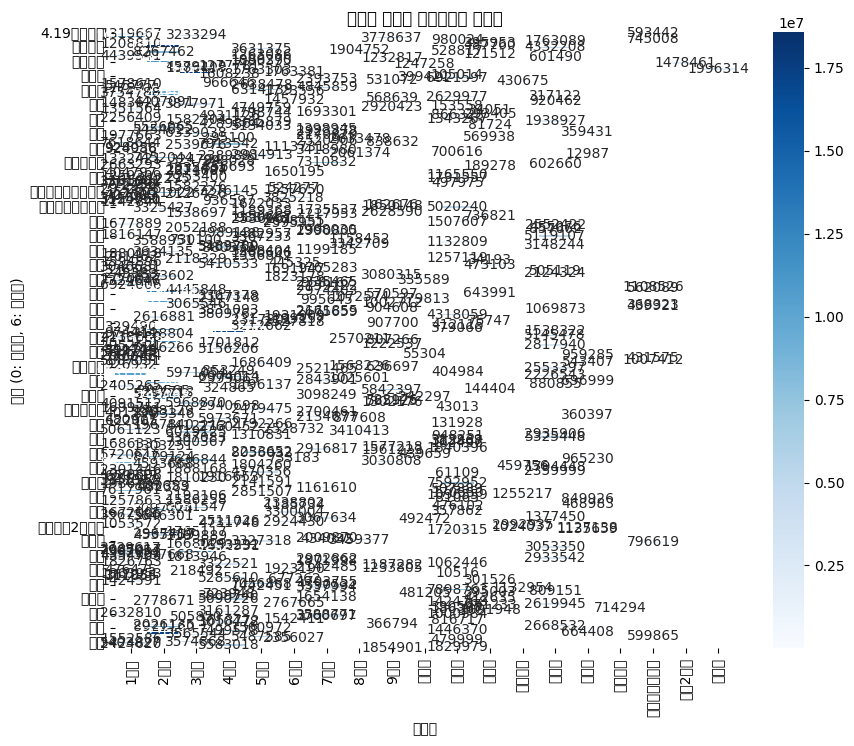

In [ ]:
#Q6 노선별(1~9호선)로 역별, 요일별 히트맵 승차승객수 비교하기

import seaborn as sns
import matplotlib.pyplot as plt

result['사용일자'] = pd.to_datetime(result['사용일자'], format='%Y%m%d')

result['연월'] = result['사용일자'].dt.to_period('M')

result['요일'] = result['사용일자'].dt.dayofweek

print(result.columns)
pivot_table = result.pivot_table(values='승차총승객수', index='역명', columns='노선명', aggfunc='sum')
print(pivot_table)

plt.figure(figsize=(10,8))
sns.heatmap(pivot_table, annot=True, fmt=".0f", cmap='Blues')

plt.title('노선별 요일별 승차승객수 히트맵')
plt.ylabel('요일 (0: 월요일, 6: 일요일)')
plt.xlabel('노선명')

plt.show()